In [18]:
import numpy as np
import os
import sys
from pathlib import Path
from volta.paths import RESULT_ROOT
from volta.plotting import *
from volta.planning.footsteps_planner import *
# from Simulation.PackageCenter import *

from volta.experiments.experiment import *


In [19]:
class ExpData:
    def __init__(self, file_path=None):
        # Metadata
        self.file_name = ""
        self.is_noisy = False
        
        # 1. Initialization of attributes (matching your .npz keys)
        self.timestamp = None
        self.walking_phase = None
        
        # Desired (Reference) Trajectories
        self.desired_com = None
        self.desired_com = None
        self.desired_lfoot = None
        self.desired_rfoot = None
        self.desired_foot_wrenches = None
        
        # Raw / Noisy Measurements
        self.raw_com = None
        self.raw_com = None
        self.raw_lfoot = None
        self.raw_rfoot = None
        
        # Estimated / Ground Truth
        self.groundtruth_com = None
        self.filtered_com = None
        self.filtered_zmp = None
        
        # Control & Dynamics
        self.grf = None
        self.torque_command = None

        if file_path:
            self.LoadFromnpz(file_path)

    def LoadFromnpz(self, file_path):
        """Loads and maps .npz data to class attributes."""
        path = Path(file_path)
        self.file_name = path.stem
        self.is_noisy = "_noise" in self.file_name
        
        with np.load(path) as data:
            # Mapping keys from your np.savez_compressed call
            self.timestamp             = data.get('timestamp')
            self.walking_phase         = data.get('walking_phase')
            
            # Desired
            self.desired_zmp           = data.get('desired_zmp')
            self.desired_com           = data.get('desired_com')
            self.desired_lfoot         = data.get('desired_lfoot')
            self.desired_rfoot         = data.get('desired_rfoot')
            self.desired_foot_wrenches = data.get('desired_foot_wrenches')
            
            # Raw
            self.raw_zmp               = data.get('raw_ZMP')  # Note: matches your 'raw_ZMP' key
            self.raw_com               = data.get('raw_com')
            self.raw_lfoot             = data.get('raw_lfoot')
            self.raw_rfoot             = data.get('raw_rfoot')
            
            # Estimated
            self.groundtruth_com       = data.get('groundtruth_CoM')
            self.filtered_com          = data.get('filtered_CoM')
            self.filtered_zmp          = data.get('filtered_ZMP')
            
            # Control
            self.grf                   = data.get('GRF')
            self.torque_command        = data.get('torque_command')

    def __repr__(self):
        status = "[NOISY]" if self.is_noisy else "[CLEAN]"
        return f"<ExpData {status}: {self.file_name}>"

In [20]:
folder_name = f"{RESULT_ROOT}/Final/Data/"
file_name_1 = "Fz_with_ref.npz"
file_name_2 = "Fz_without_ref.npz"
full_path_1 = os.path.join(folder_name, file_name_1)
full_path_2 = os.path.join(folder_name, file_name_2)
# 2. Load the file
try:
    loaded_data_1 = np.load(full_path_1)
    loaded_data_2 = np.load(full_path_2)

except FileNotFoundError:
    print(f"Error: The file was not found.")

In [21]:
time:np.ndarray                = loaded_data_1['timestamp']
Fz_L_ref = loaded_data_1['Fz_L']
Fz_R_ref = loaded_data_1['Fz_R']
Fz_L_no_ref = loaded_data_2['Fz_L']
Fz_R_no_ref = loaded_data_2['Fz_R']
exp_2a_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_2a_noise.npz")

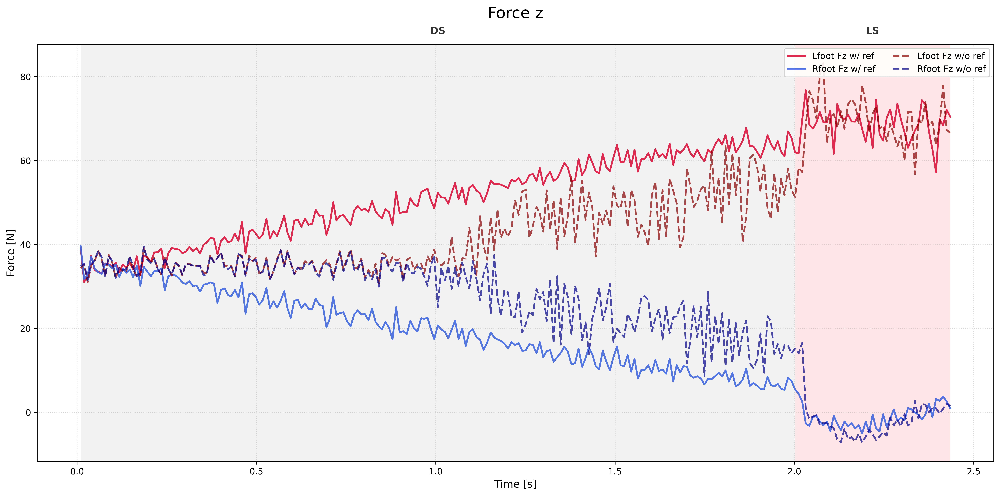

In [22]:
PlotGRF(
    time_data     = time[::100],
    walking_phase = exp_2a_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [Fz_L_ref,   "Lfoot Fz w/ ref"],
    plot_2 = [Fz_R_ref, "Rfoot Fz w/ ref"],
    plot_3 = [Fz_L_no_ref,   "Lfoot Fz w/o ref"],
    plot_4 = [Fz_R_no_ref, "Rfoot Fz w/o ref"],
    
    plot_interval = [0.01,2.5], # Plots the full duration
    title         = "Force z",
    ylabel        = "Force [N]"
)

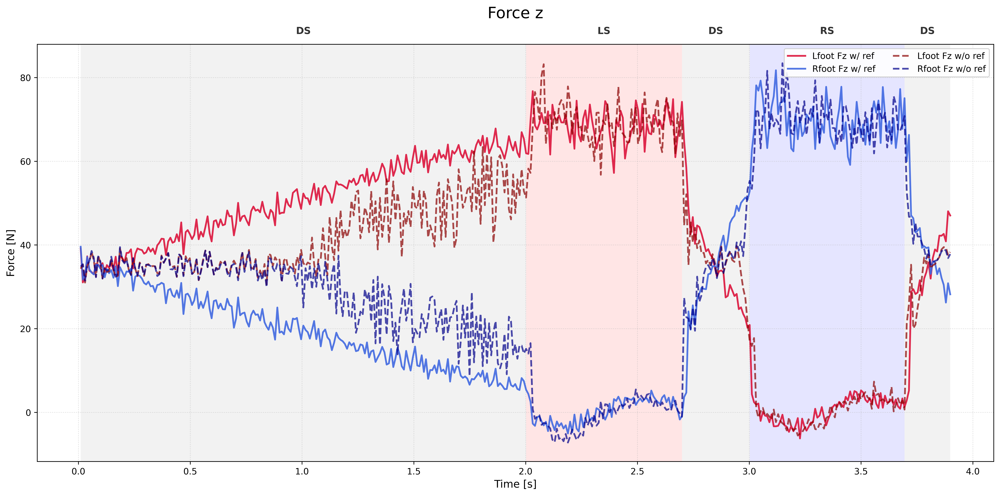

In [26]:
PlotGRF(
    time_data     = time[::100],
    walking_phase = exp_2a_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [Fz_L_ref,   "Lfoot Fz w/ ref"],
    plot_2 = [Fz_R_ref, "Rfoot Fz w/ ref"],
    plot_3 = [Fz_L_no_ref,   "Lfoot Fz w/o ref"],
    plot_4 = [Fz_R_no_ref, "Rfoot Fz w/o ref"],
    
    plot_interval = [0.01,4.0], # Plots the full duration
    title         = "Force z",
    ylabel        = "Force [N]"
)

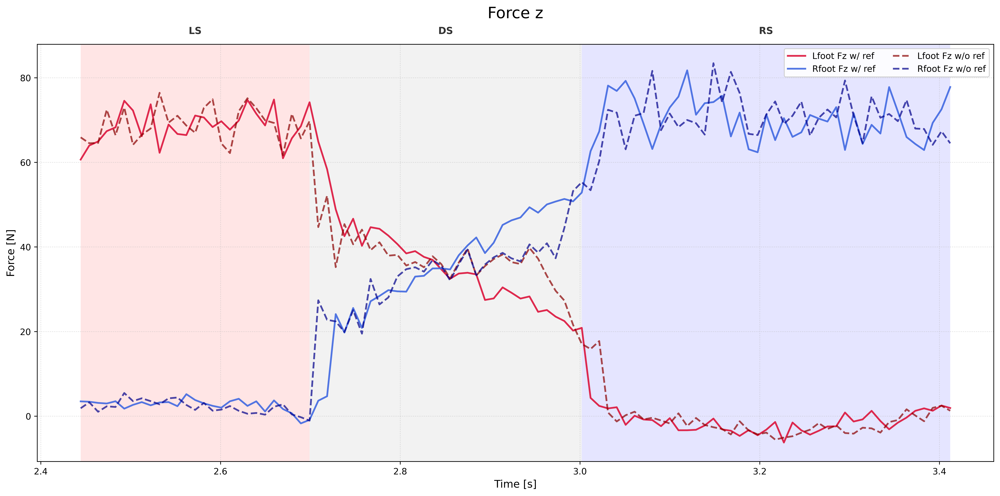

In [24]:
PlotGRF(
    time_data     = time[::100],
    walking_phase = exp_2a_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [Fz_L_ref,   "Lfoot Fz w/ ref"],
    plot_2 = [Fz_R_ref, "Rfoot Fz w/ ref"],
    plot_3 = [Fz_L_no_ref,   "Lfoot Fz w/o ref"],
    plot_4 = [Fz_R_no_ref, "Rfoot Fz w/o ref"],
    
    plot_interval = [2.5,3.5], # Plots the full duration
    title         = "Force z",
    ylabel        = "Force [N]"
)

### Rigid vs Compliant

In [8]:
exp_1f_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_1f_noise.npz")
exp_2a_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_2a_noise.npz")
exp_2c_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_2c_noise.npz")
save_path = f"{RESULT_ROOT}/Final/Pics/others"

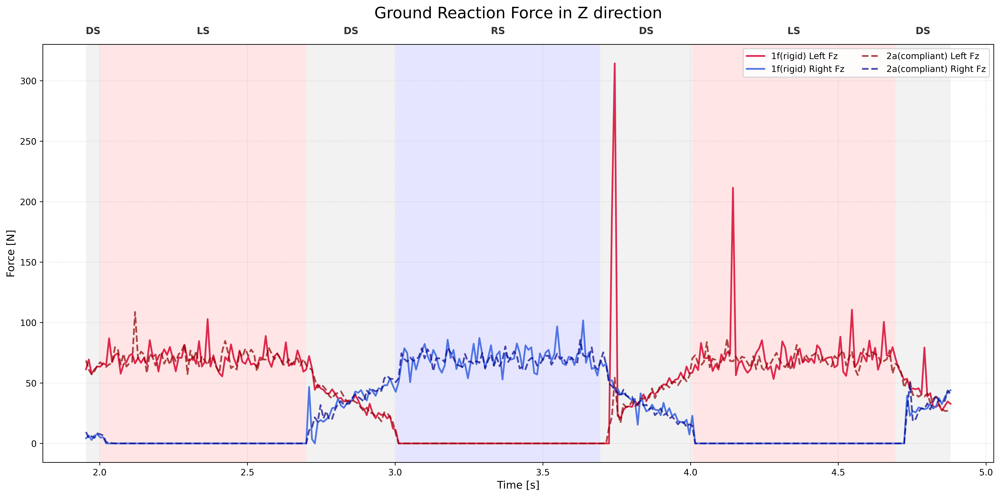

In [9]:
# Mapping your 'exp_1f_noise' data to the structured [data, "label"] format
PlotGRF(
    time_data     = exp_1f_noise.timestamp[::100],
    walking_phase = exp_1f_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [exp_1f_noise.grf[5,::100],   "1f(rigid) Left Fz"],
    plot_2 = [exp_1f_noise.grf[11,::100], "1f(rigid) Right Fz"],
    plot_3 = [exp_2a_noise.grf[5,::100],  "2a(compliant) Left Fz"],
    plot_4 = [exp_2a_noise.grf[11,::100], "2a(compliant) Right Fz"],
    
    plot_interval = [2,5], # Plots the full duration
    title         = "Ground Reaction Force in Z direction",
    ylabel        = "Force [N]"
)

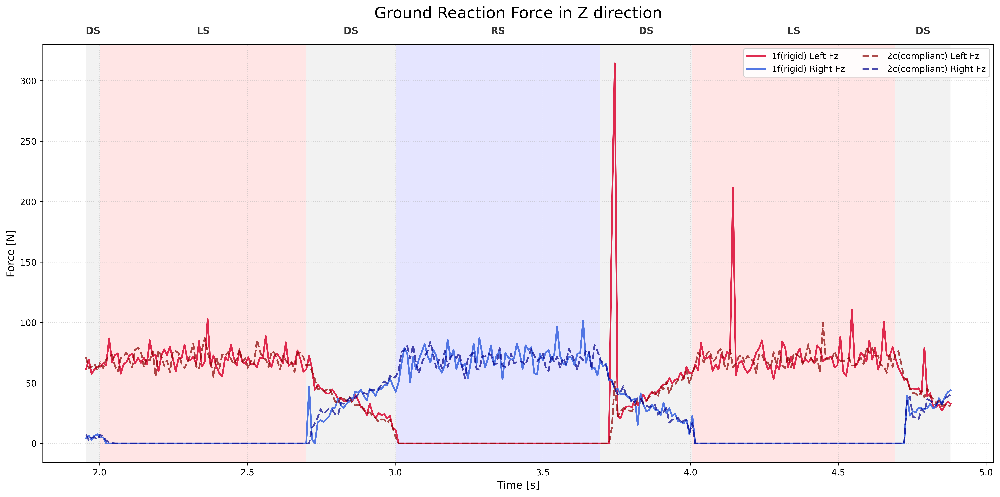

In [10]:
PlotGRF(
    time_data     = exp_1f_noise.timestamp[::100],
    walking_phase = exp_1f_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [exp_1f_noise.grf[5,::100],   "1f(rigid) Left Fz"],
    plot_2 = [exp_1f_noise.grf[11,::100], "1f(rigid) Right Fz"],
    plot_3 = [exp_2c_noise.grf[5,::100],  "2c(compliant) Left Fz"],
    plot_4 = [exp_2c_noise.grf[11,::100], "2c(compliant) Right Fz"],
    
    plot_interval = [2,5], # Plots the full duration
    title         = "Ground Reaction Force in Z direction",
    ylabel        = "Force [N]"
)

In [11]:
PlotGRF(
    time_data     = exp_1f_noise.timestamp[::100],
    walking_phase = exp_1f_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [exp_2a_noise.grf[0,::100],   "2a(compliant) Left Nx"],
    plot_2 = [exp_2a_noise.grf[6,::100], "2a(compliant) Right Nx"],
    plot_3 = [exp_2c_noise.grf[0,::100],  "2c(compliant) Left Nx"],
    plot_4 = [exp_2c_noise.grf[6,::100], "2c(compliant) Right Nx"],
    
    plot_interval = [2,10], # Plots the full duration
    title         = "Moment X",
    ylabel        = "Moment [Nm]"
)

KeyboardInterrupt: 

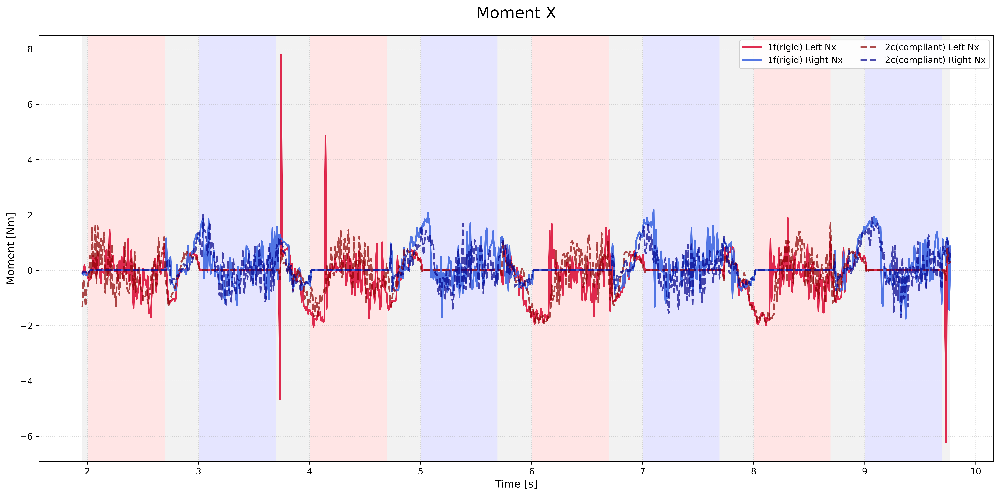

In [ ]:
PlotGRF(
    time_data     = exp_1f_noise.timestamp[::100],
    walking_phase = exp_1f_noise.walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [exp_1f_noise.grf[0,::100],   "1f(rigid) Left Nx"],
    plot_2 = [exp_1f_noise.grf[6,::100], "1f(rigid) Right Nx"],
    plot_3 = [exp_2c_noise.grf[0,::100],  "2c(compliant) Left Nx"],
    plot_4 = [exp_2c_noise.grf[6,::100], "2c(compliant) Right Nx"],
    
    plot_interval = [2,10], # Plots the full duration
    title         = "Moment X",
    ylabel        = "Moment [Nm]"
)

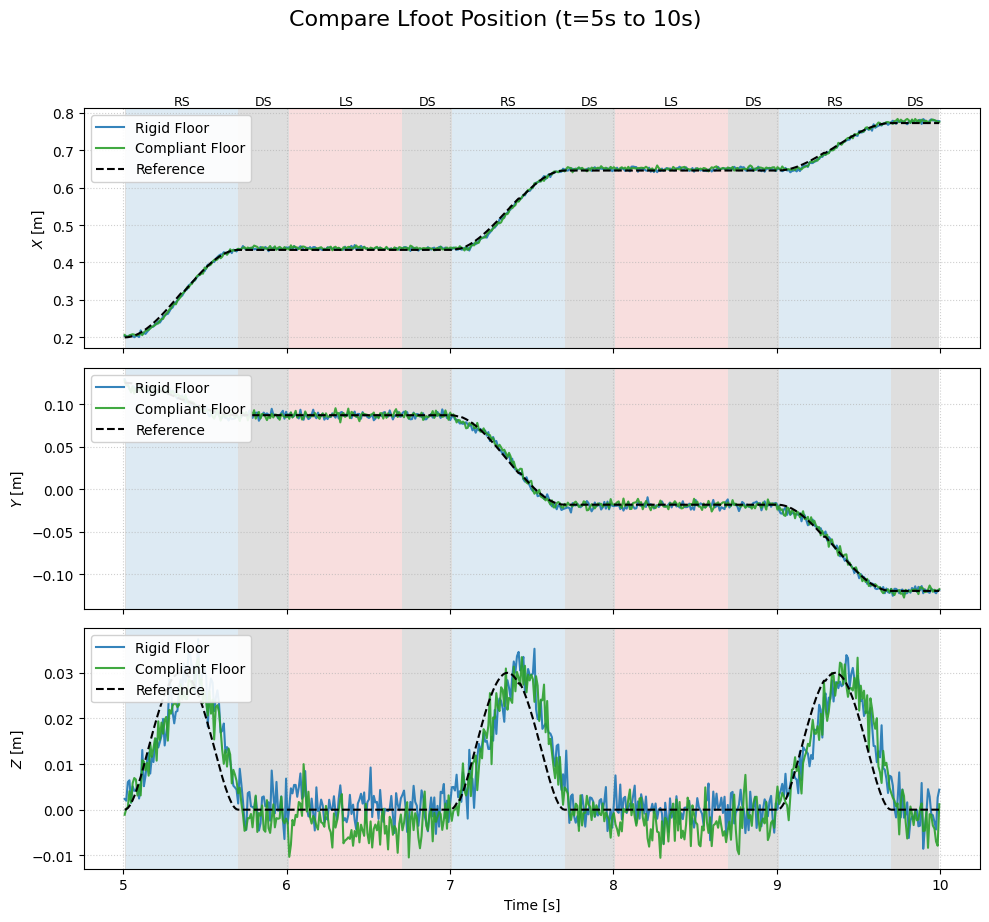

In [ ]:
PlotTrackingCompare(
    time_log=exp_1f_noise.timestamp[::100], 
    ref_data=exp_1f_noise.desired_lfoot[3:6,::100], 
    act_data=[exp_1f_noise.raw_lfoot[3:6,::100], exp_2a_noise.raw_lfoot[3:6,::100]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_1f_noise.walking_phase[::100], 
    act_labels=["Rigid Floor","Compliant Floor"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="Compare Lfoot Position",
    plot_interval=[5,10],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

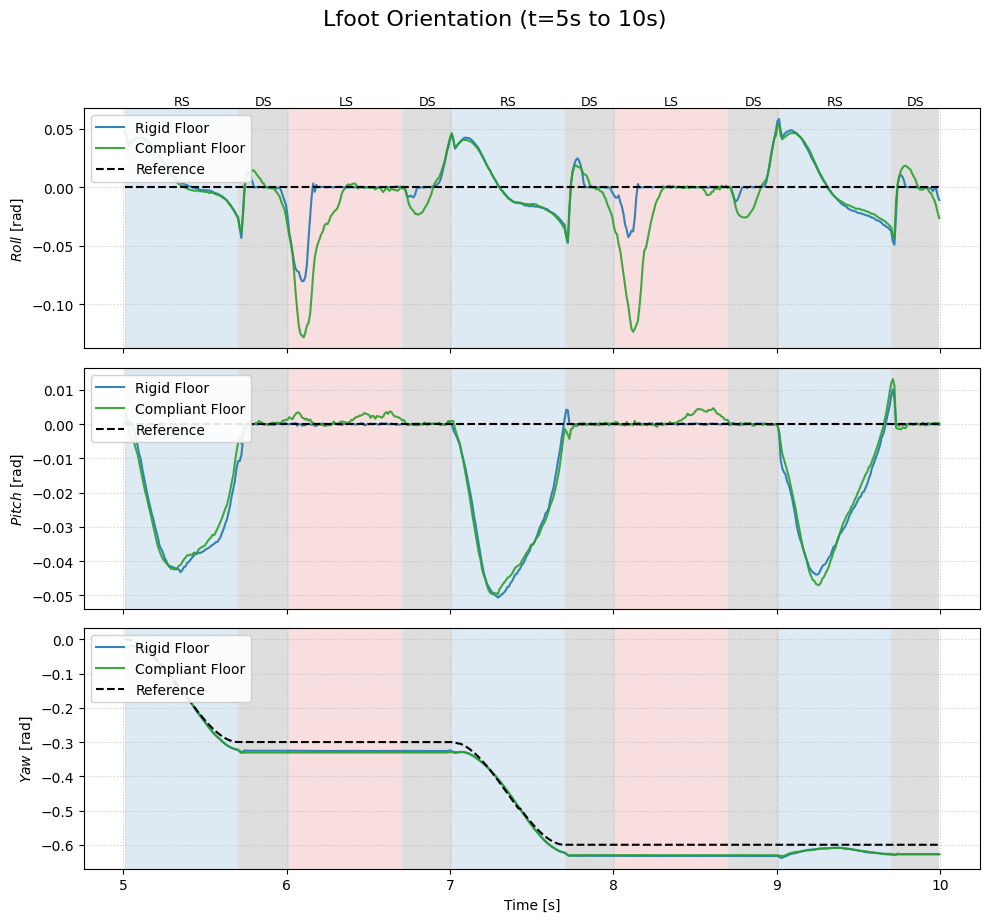

In [ ]:
PlotTrackingCompare(
    time_log=exp_1f_noise.timestamp[::100], 
    ref_data=exp_1f_noise.desired_lfoot[0:3,::100], 
    act_data=[exp_1f_noise.raw_lfoot[0:3,::100], exp_2a_noise.raw_lfoot[0:3,::100]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_1f_noise.walking_phase[::100], 
    act_labels=["Rigid Floor","Compliant Floor"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['Roll', 'Pitch', 'Yaw'], 
    unit='rad',
    title="Lfoot Orientation",
    plot_interval=[5,10],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

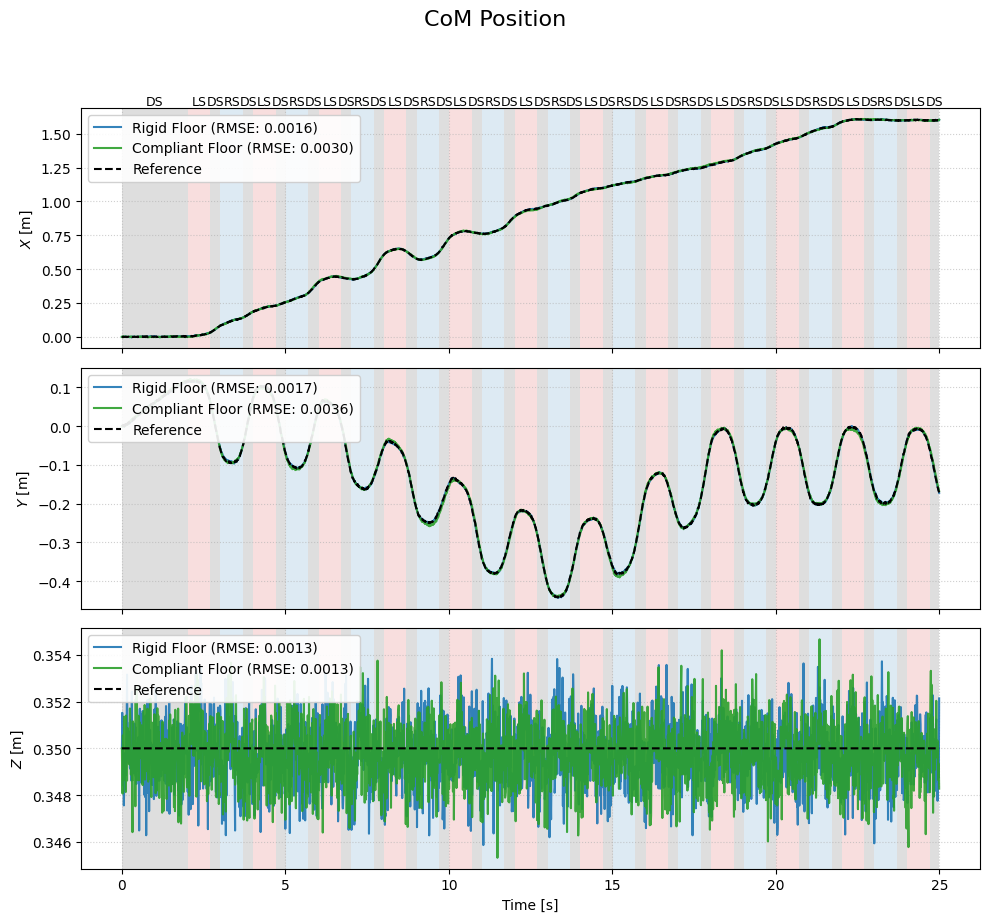

In [ ]:
PlotTrackingCompare(
    time_log=exp_1f_noise.timestamp[::100], 
    ref_data=exp_1f_noise.desired_com[3:6,::100], 
    act_data=[exp_1f_noise.filtered_com[3:6,::100], exp_2a_noise.filtered_com[3:6,::100]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_1f_noise.walking_phase[::100], 
    act_labels=["Rigid Floor","Compliant Floor"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="CoM Position",
    plot_interval=None,
    show_error=False,
    save_folder=None,
    show_plot = True
)

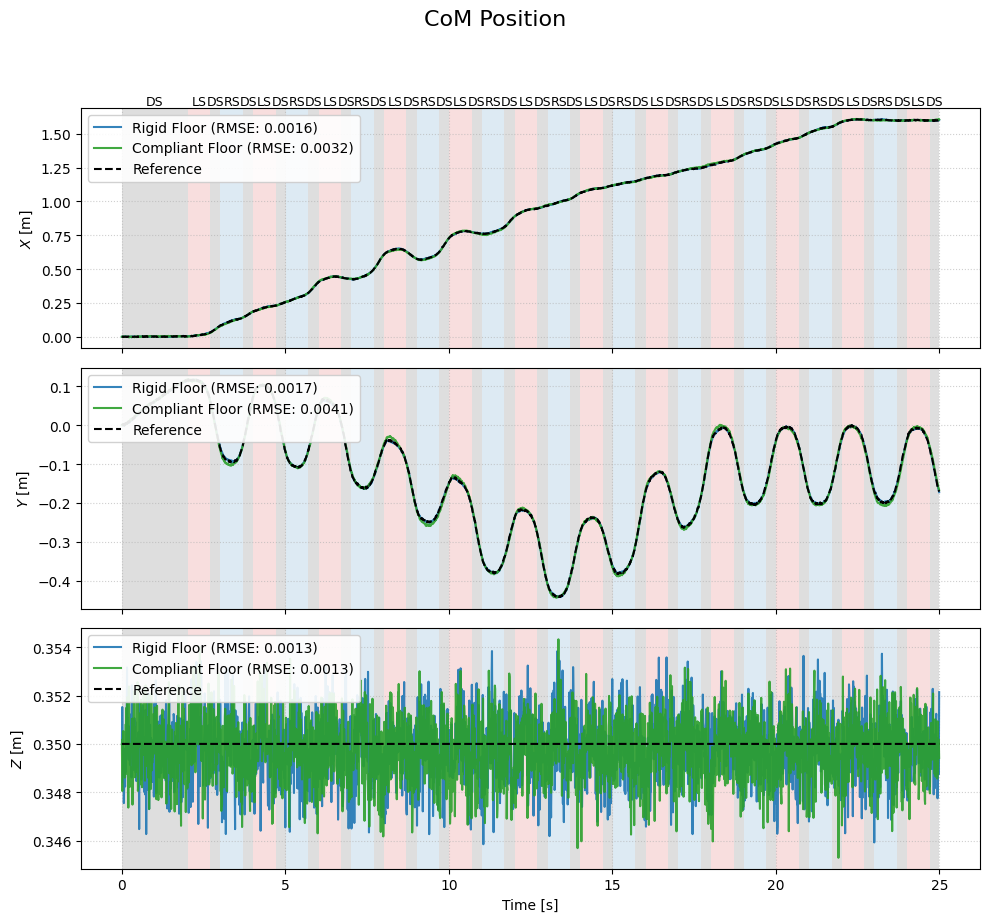

In [ ]:
PlotTrackingCompare(
    time_log=exp_1f_noise.timestamp[::100], 
    ref_data=exp_1f_noise.desired_com[3:6,::100], 
    act_data=[exp_1f_noise.filtered_com[3:6,::100], exp_2c_noise.filtered_com[3:6,::100]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_1f_noise.walking_phase[::100], 
    act_labels=["Rigid Floor","Compliant Floor"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="CoM Position",
    plot_interval=None,
    show_error=False,
    save_folder=None,
    show_plot = True
)

### External force

In [ ]:
exp_7a_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_7a_noise.npz")
exp_7b_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_7b_noise.npz")
exp_7c_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_7c_noise.npz")
exp_7d_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_7d_noise.npz")
exp_config = ExperimentConfig(exp_name="dummy",profile_type="straight_10")
params = {
'g': 9.81,
'h': 0.35,
'foot_size': 0.08,
'step_height': 0.03,
'ss_duration': 70,
'ds_duration': 30, 
'mpc_time_step': 0.01,
'first_swing': 'rfoot',
'first_stance': 'lfoot',
'N': 100,
}
save_path = f"{RESULT_ROOT}/Final/Pics/others/compare_exp_7"
planner = FootstepsPlanner(params=params)
initial_pos = [0.0,0.125,0.0]
plan = planner.PlanFootsteps(initial_pos, exp_config.VRefCommand, np.clip(4,min=1.0), params['first_stance'])

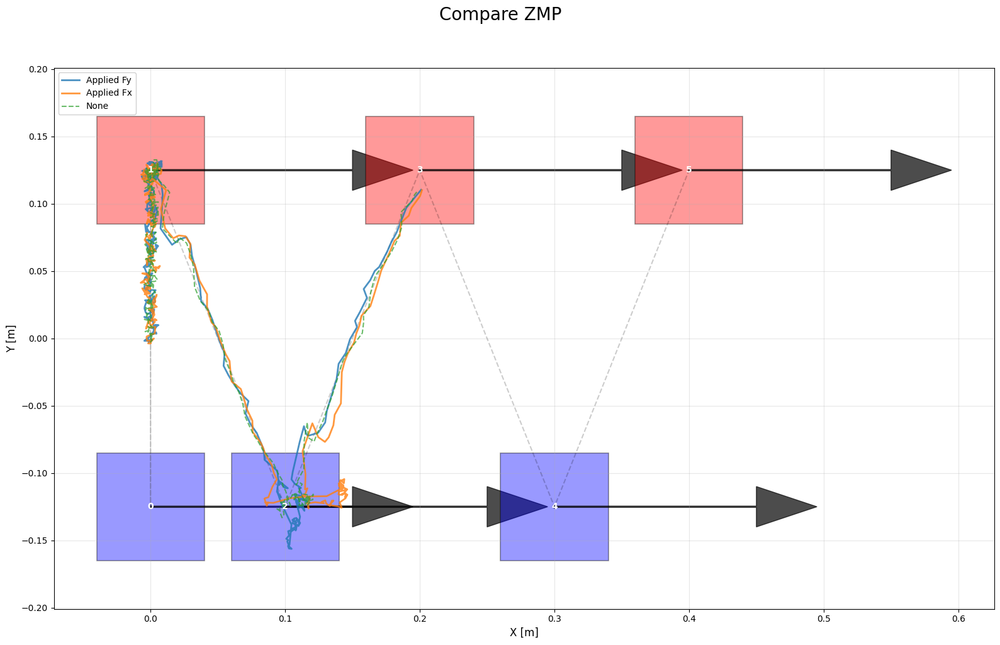

In [ ]:
PlotFootsteps(
    steps=plan,
    plot_3=[exp_7d_noise.filtered_zmp[0, 500::100], exp_7d_noise.filtered_zmp[1, 500::100], "None"],
    plot_2=[exp_7a_noise.filtered_zmp[0, 500::100], exp_7a_noise.filtered_zmp[1, 500::100], "Applied Fx"],
    plot_1=[exp_7b_noise.filtered_zmp[0, 500::100], exp_7b_noise.filtered_zmp[1, 500::100], "Applied Fy"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"Compare ZMP"
)

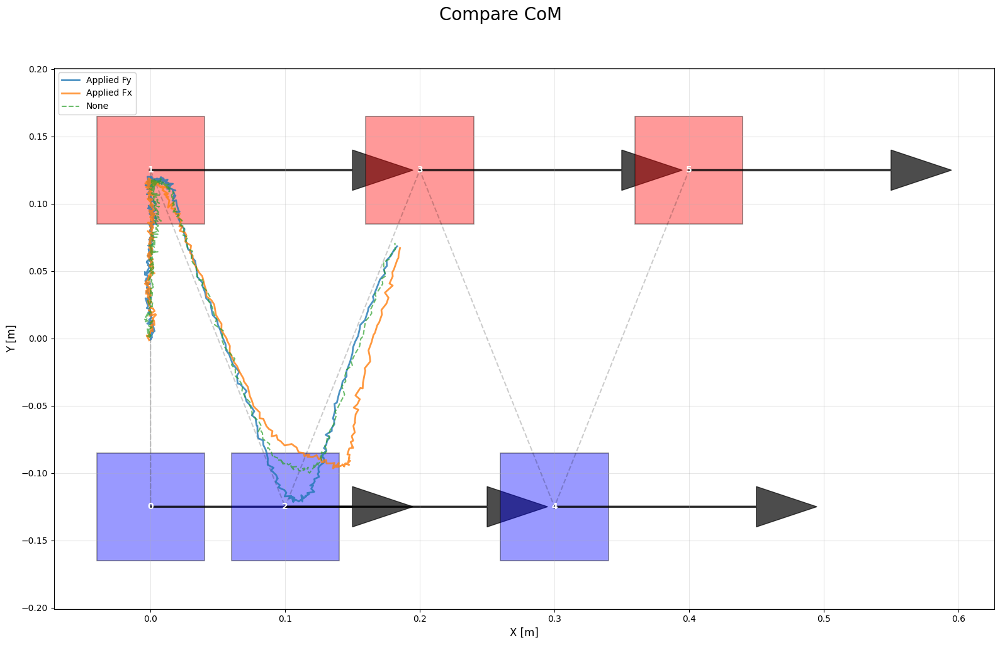

In [ ]:
PlotFootsteps(
    steps=plan,
    plot_3=[exp_7d_noise.filtered_com[3, 500::100], exp_7d_noise.filtered_com[4, 500::100], "None"],
    plot_2=[exp_7a_noise.filtered_com[3, 500::100], exp_7a_noise.filtered_com[4, 500::100], "Applied Fx"],
    plot_1=[exp_7b_noise.filtered_com[3, 500::100], exp_7b_noise.filtered_com[4, 500::100], "Applied Fy"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"Compare CoM"
)

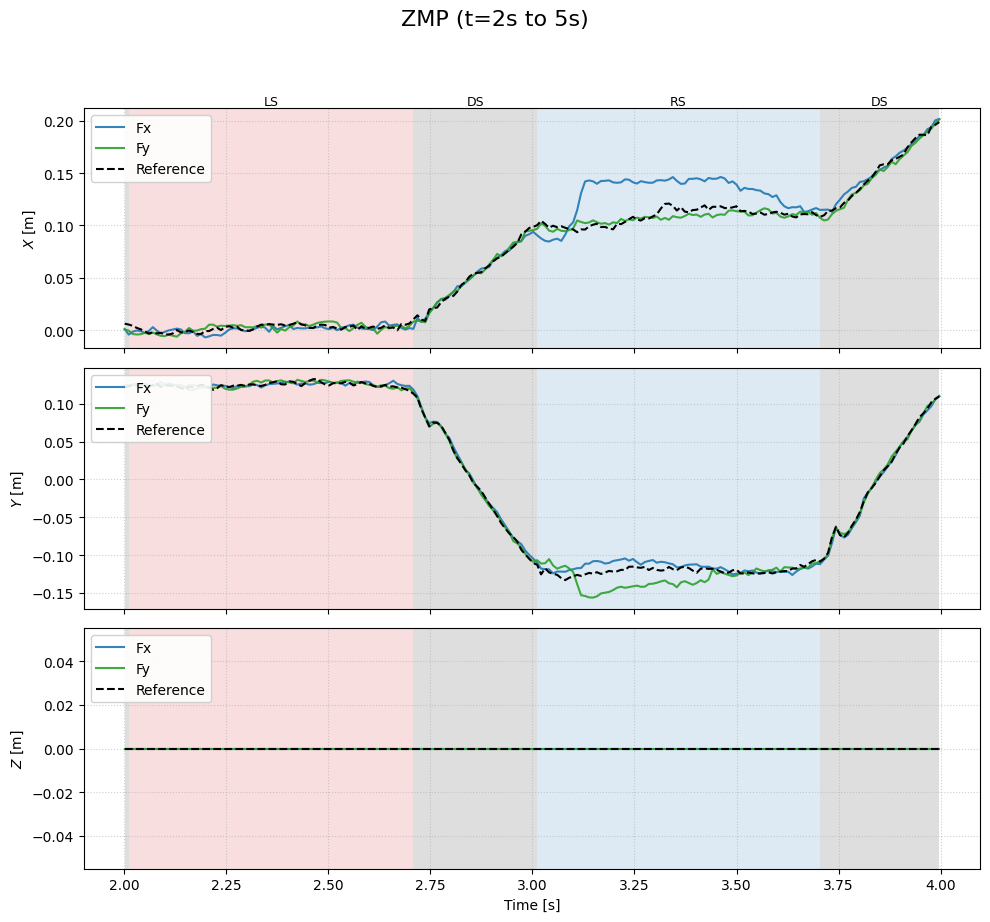

In [ ]:
PlotTrackingCompare(
    time_log=exp_7d_noise.timestamp[::100], 
    ref_data=exp_7d_noise.filtered_zmp[:,::100], 
    act_data=[exp_7a_noise.filtered_zmp[:,::100], exp_7b_noise.filtered_zmp[:,::100]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_7d_noise.walking_phase[::100], 
    act_labels=["Fx","Fy"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="ZMP",
    plot_interval=[2,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

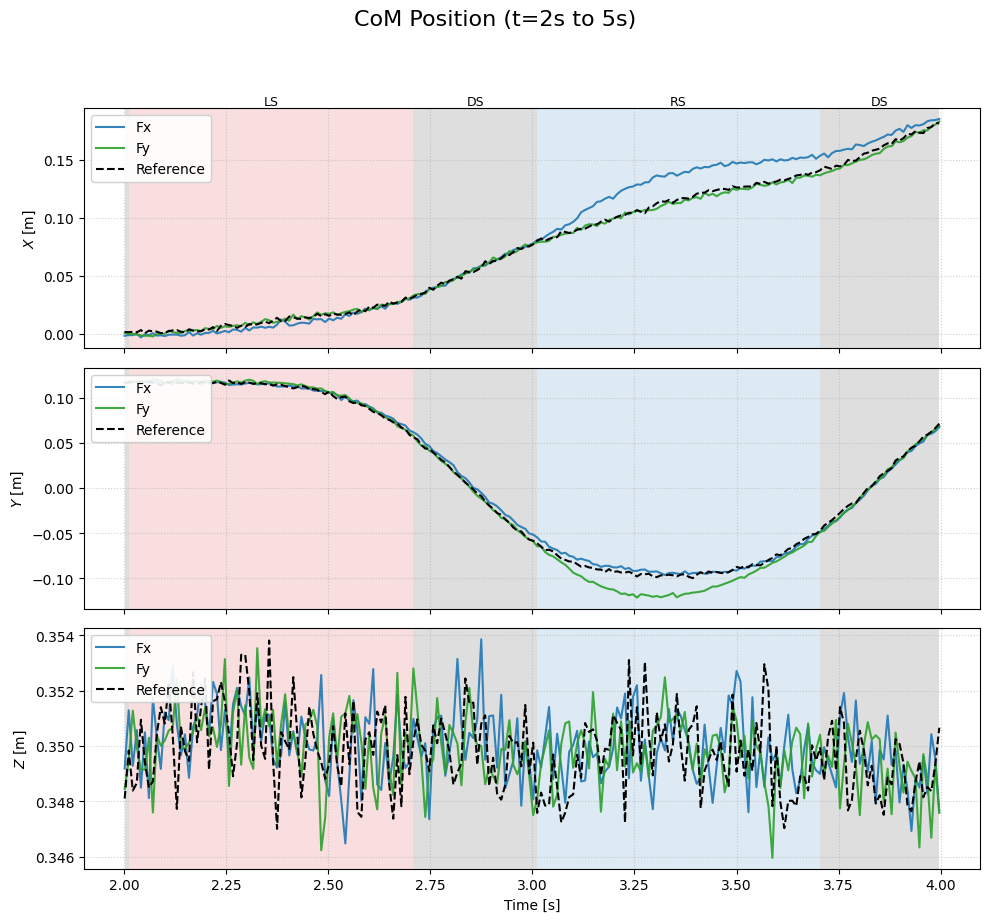

In [ ]:
PlotTrackingCompare(
    time_log=exp_7d_noise.timestamp[::100], 
    ref_data=exp_7d_noise.filtered_com[3:6,::100], 
    act_data=[exp_7a_noise.filtered_com[3:6,::100], exp_7b_noise.filtered_com[3:6,::100]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_7d_noise.walking_phase[::100], 
    act_labels=["Fx","Fy"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="CoM Position",
    plot_interval=[2,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)


### Compare floor dissipation

In [ ]:
exp_3d_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_3e_noise.npz")
exp_3e_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_3d_noise.npz")
save_path = f"{RESULT_ROOT}/Final/Pics/others"

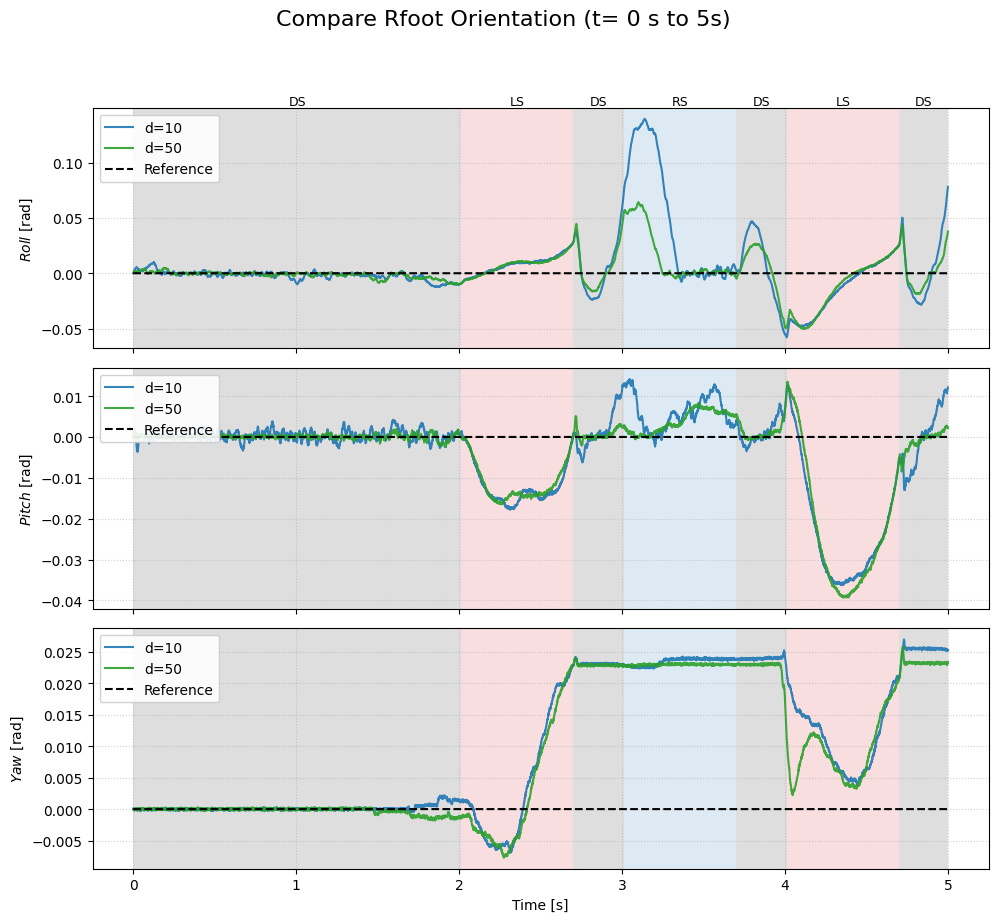

In [ ]:
PlotTrackingCompare(
    time_log=exp_3d_noise.timestamp[::10], 
    ref_data=exp_3d_noise.desired_rfoot[0:3,::10], 
    act_data=[exp_3d_noise.raw_rfoot[0:3,::10], exp_3e_noise.raw_rfoot[0:3,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_3d_noise.walking_phase[::10], 
    act_labels=["d=10","d=50"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['Roll', 'Pitch', 'Yaw'], 
    unit='rad',
    title="Compare Rfoot Orientation",
    plot_interval=[0,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

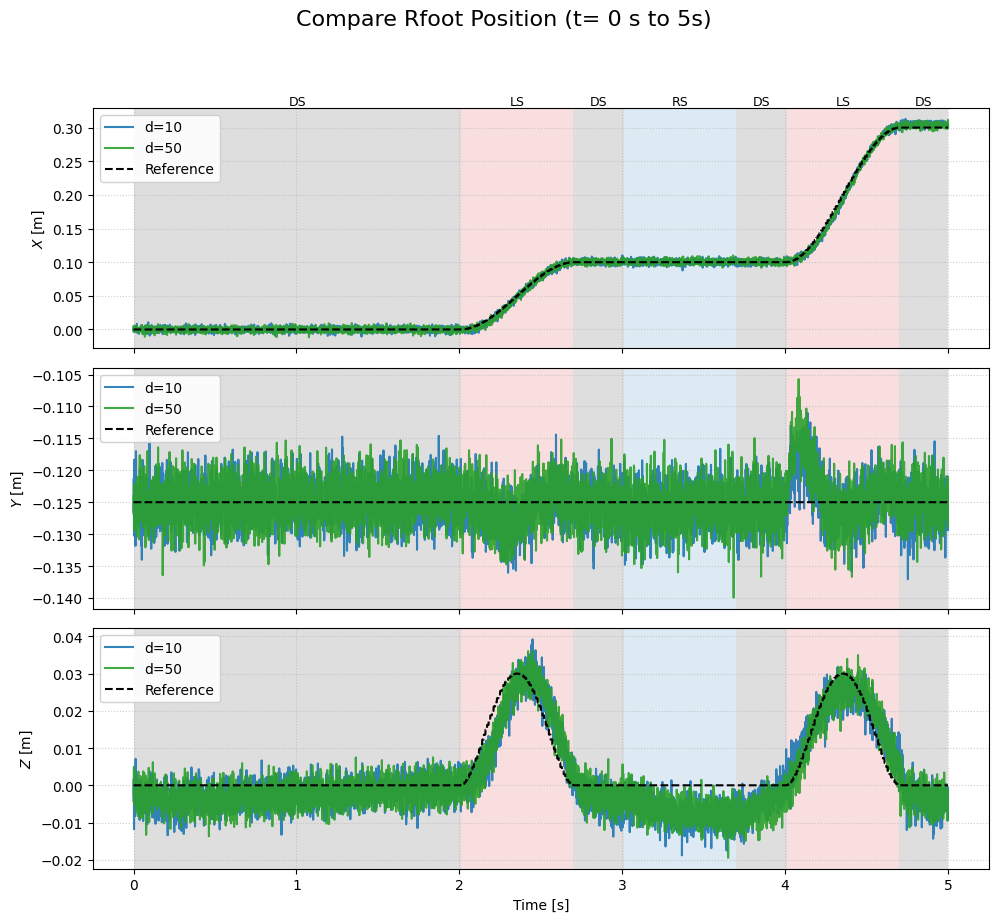

In [ ]:
PlotTrackingCompare(
    time_log=exp_3d_noise.timestamp[::10], 
    ref_data=exp_3d_noise.desired_rfoot[3:6,::10], 
    act_data=[exp_3d_noise.raw_rfoot[3:6,::10], exp_3e_noise.raw_rfoot[3:6,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_3d_noise.walking_phase[::10], 
    act_labels=["d=10","d=50"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="Compare Rfoot Position",
    plot_interval=[0,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

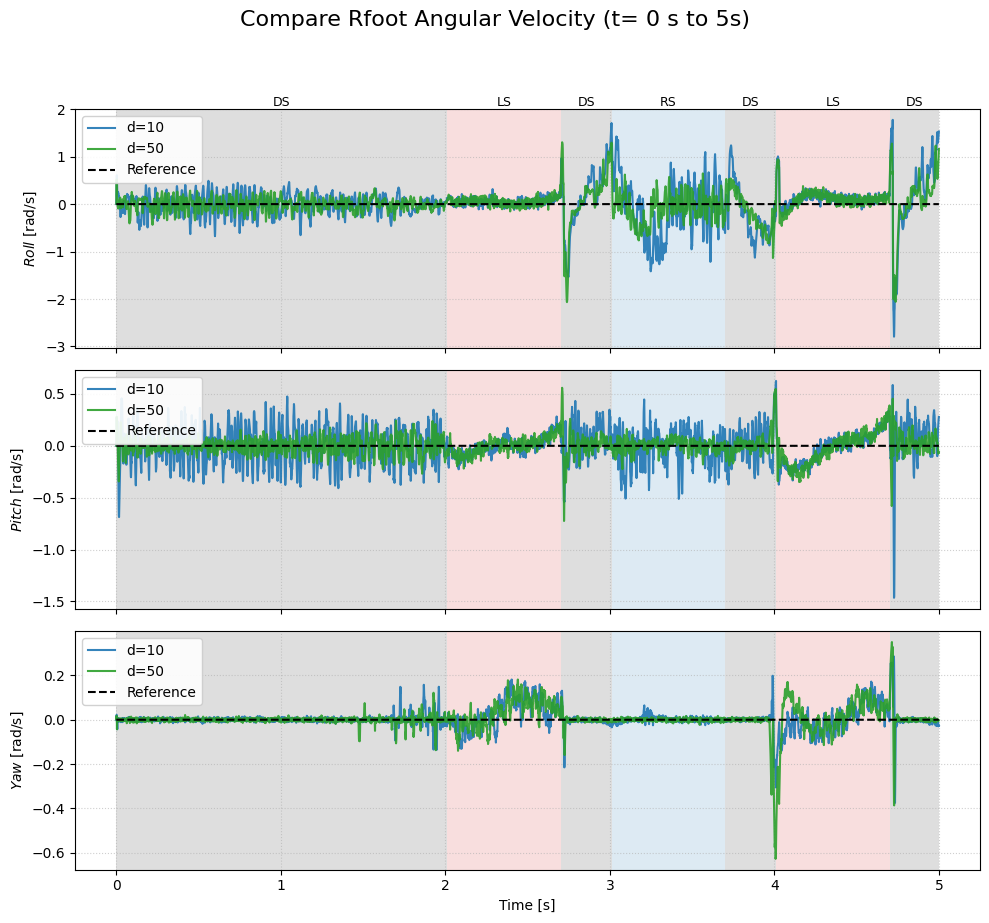

In [ ]:
PlotTrackingCompare(
    time_log=exp_3d_noise.timestamp[::10], 
    ref_data=exp_3d_noise.desired_rfoot[6:9,::10], 
    act_data=[exp_3d_noise.raw_rfoot[6:9,::10], exp_3e_noise.raw_rfoot[6:9,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_3d_noise.walking_phase[::10], 
    act_labels=["d=10","d=50"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['Roll', 'Pitch', 'Yaw'], 
    unit='rad/s',
    title="Compare Rfoot Angular Velocity",
    plot_interval=[0,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

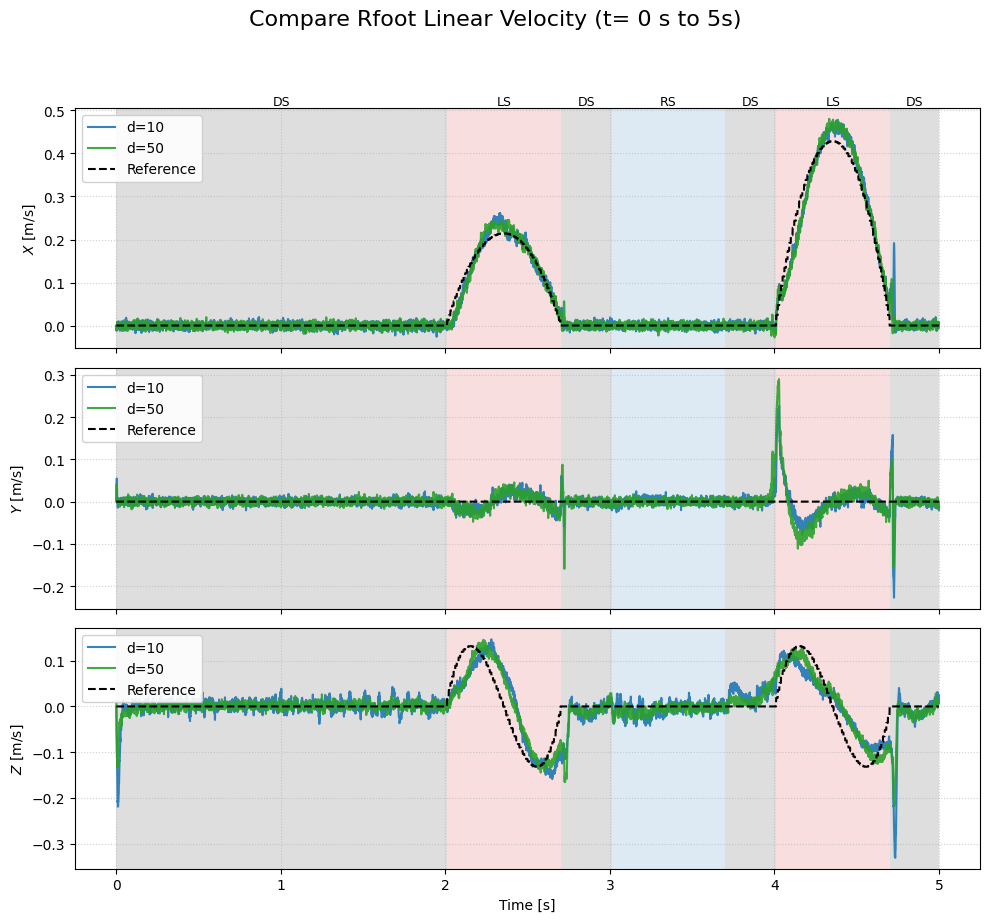

In [ ]:
PlotTrackingCompare(
    time_log=exp_3d_noise.timestamp[::10], 
    ref_data=exp_3d_noise.desired_rfoot[9:12,::10], 
    act_data=[exp_3d_noise.raw_rfoot[9:12,::10], exp_3e_noise.raw_rfoot[9:12,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_3d_noise.walking_phase[::10], 
    act_labels=["d=10","d=50"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m/s',
    title="Compare Rfoot Linear Velocity",
    plot_interval=[0,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)

### St leg Stabilizer

In [ ]:
exp_3f_noise = ExpData(f"{RESULT_ROOT}/Final/Data/exp_3f_noise.npz")

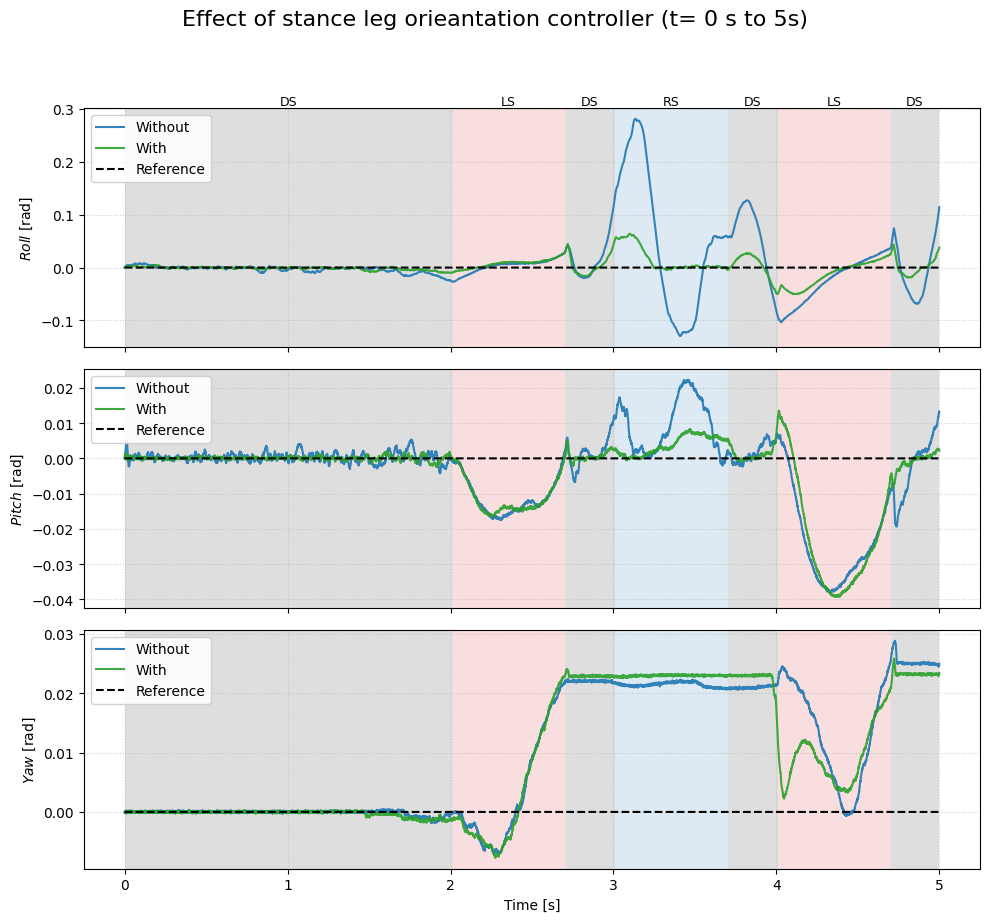

In [ ]:
PlotTrackingCompare(
    time_log=exp_3e_noise.timestamp[::10], 
    ref_data=exp_3e_noise.desired_rfoot[0:3,::10], 
    act_data=[exp_3f_noise.raw_rfoot[0:3,::10], exp_3e_noise.raw_rfoot[0:3,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=exp_3e_noise.walking_phase[::10], 
    act_labels=["Without","With"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['Roll', 'Pitch', 'Yaw'], 
    unit='rad',
    title="Effect of stance leg orieantation controller",
    plot_interval=[0,5],
    show_error=False,
    save_folder=save_path,
    show_plot = True,
    show_rms=False
)